# Timestral vs classical benchmarks on retail demand (M5)

**Timestral** is Mistral AI's family of zero-shot foundation models for time series, released on
15 October 2026. This notebook puts it to work on a real demand forecasting problem, the Walmart **M5**
dataset, and compares it with the methods a demand planner would use today, all evaluated with the same
protocol:

| Family | Models | Library |
|---|---|---|
| Baselines | 28-day moving average, Naive, SeasonalNaive (7), Croston SBA | `statsforecast` |
| Time series | AutoARIMA, AutoETS, AutoCES (weekly seasonality) | `statsforecast` |
| Machine learning | global Tweedie LightGBM: plain, level-normalised, level-normalised with direct strategy | `mlforecast` |
| Foundation model | Timestral 28M: history only, with known covariates, with a past covariate, multivariate | `timestral` |
| Ensembles | equal-weight averages of Timestral, LightGBM and a statistical model | |

**Questions**

1. How is Timestral called, and what exactly does it receive as input?
2. How do you judge a demand forecast? WMAPE alone is misleading on intermittent demand.
3. Does Timestral beat the benchmarks, zero-shot? Where does it win and where does it lose?
4. Do past covariates, multivariate forecasting or ensembles help?
5. Does the ranking survive holiday periods and evaluation at the level of the replenishment decision?
6. What are the limits and pitfalls of Timestral found along the way?

The notebook runs the whole benchmark itself. The first run downloads M5, computes every model and caches
the forecasts in `data/processed/` (about two and a half hours on CPU); later runs read them back in
seconds. Deleting a `fc_*.parquet` file recomputes only that model.

## 0. Setup

In [1]:
import logging
import os
import time
import warnings

# must be set before numpy and torch are imported
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
warnings.filterwarnings(action="ignore", category=DeprecationWarning)
warnings.filterwarnings(action="ignore", message="IProgress not found")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from timestral_forecast.backtest import (run_benchmark, run_holiday_benchmark,
                                         timestral_variants)
from timestral_forecast.config import Settings
from timestral_forecast.data import download_m5, load_or_build
from timestral_forecast.ensemble import ENSEMBLES, add_ensembles
from timestral_forecast.metrics import (aggregate_periods, bias, coverage, evaluate, fold_table,
                                        forecast_value_added, score, weighted_quantile_loss, wmape)
from timestral_forecast.models.lgbm import LGBM_VARIANTS
from timestral_forecast.models.timestral_model import load_timestral, prepare_inputs, quantile_column
from timestral_forecast.multivariate import affinity_groups, weekly_profiles
from timestral_forecast.plotting import (FIG_WIDTH, plot_heatmap, plot_sales_overview,
                                         plot_score_bars, plot_segment_examples,
                                         plot_series_forecast, plot_timestral_inputs,
                                         plot_wmape_bias)
from timestral_forecast.preprocessing import (backtest_cutoffs, build_timestral_arrays,
                                              mask_constant_covariate, split_at, store_of,
                                              store_totals)
from timestral_forecast.segmentation import adi_cv2_class

logging.basicConfig(level=logging.WARNING)
sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

The experiment settings live in `timestral_forecast.config.Settings`; every field can be overridden
with a `TF_*` environment variable or a `.env` file (see `.env.example`). The ones that shape the analysis:

In [2]:
settings = Settings()

settings.model_dump(include={"dept_id", "store_ids", "horizon", "n_windows", "holiday_cutoffs",
                             "timestral_models", "timestral_max_context", "timestral_group_size"})

{'dept_id': 'FOODS_3',
 'store_ids': ('CA_1', 'TX_1', 'WI_1'),
 'horizon': 28,
 'n_windows': 3,
 'holiday_cutoffs': (datetime.date(2015, 6, 21),
  datetime.date(2015, 11, 22),
  datetime.date(2015, 12, 20)),
 'timestral_models': ('mistralai/Timestral-28M',),
 'timestral_max_context': 1024,
 'timestral_group_size': 4}

## 1. Data: an M5 subset

M5 is the dataset of the Walmart forecasting competition: daily unit sales per item and store, with
prices, events and SNAP days (the days food-stamp benefits are paid out). We keep department **FOODS_3**
in three stores of three states (CA_1, TX_1, WI_1). The archive comes from Nixtla's public mirror and is
turned into the long format `unique_id, ds, y` used by the Nixtla suite:

* `y_df`: the target, one row per series and day;
* `x_df`: covariates known in advance (price, SNAP day, event flag and type);
* `s_df`: static attributes, one row per series.

In [3]:
zip_path = download_m5(url=settings.m5_url, raw_dir=settings.raw_dir)
data = load_or_build(zip_path, cache_dir=settings.processed_dir, dept_id=settings.dept_id,
                     store_ids=settings.store_ids)
y_df, x_df, s_df = data.y_df, data.x_df, data.s_df

print(f"{y_df.unique_id.nunique():,} series x {y_df.ds.nunique():,} days "
      f"({y_df.ds.min().date()} -> {y_df.ds.max().date()}), {len(y_df):,} rows")

2,469 series x 1,941 days (2011-01-29 -> 2016-05-22), 4,792,329 rows


`y_df` holds the target: units sold per series (`unique_id` = item and store) and day. Every series
starts on the first M5 date, so items launched later begin with a run of zeros that are not demand.

In [4]:
y_df.head()

,unique_id,ds,y
0,FOODS_3_001_CA_1,2011-01-29,1.0
1,FOODS_3_002_CA_1,2011-01-29,0.0
2,FOODS_3_003_CA_1,2011-01-29,0.0
3,FOODS_3_004_CA_1,2011-01-29,0.0
4,FOODS_3_005_CA_1,2011-01-29,1.0


`x_df` holds what is known in advance: the weekly `sell_price` (missing until the item goes on sale),
the 0/1 flags `snap` (food-stamp day in the store's state) and `is_event`, and the `event_type` name.

In [5]:
x_df.head()

,unique_id,ds,sell_price,snap,is_event,event_type
0,FOODS_3_001_CA_1,2011-01-29,2.28,0.0,0.0,none
1,FOODS_3_002_CA_1,2011-01-29,NaN,0.0,0.0,none
2,FOODS_3_003_CA_1,2011-01-29,NaN,0.0,0.0,none
3,FOODS_3_004_CA_1,2011-01-29,NaN,0.0,0.0,none
4,FOODS_3_005_CA_1,2011-01-29,1.98,0.0,0.0,none


`s_df` holds the static attributes of each series. LightGBM uses item and store as categorical
features; for Timestral the store defines the store total and the multivariate groups.

In [6]:
s_df.head()

,unique_id,item_id,dept_id,cat_id,store_id,state_id
0,FOODS_3_001_CA_1,FOODS_3_001,FOODS_3,FOODS,CA_1,CA
1,FOODS_3_002_CA_1,FOODS_3_002,FOODS_3,FOODS,CA_1,CA
2,FOODS_3_003_CA_1,FOODS_3_003,FOODS_3,FOODS,CA_1,CA
3,FOODS_3_004_CA_1,FOODS_3_004,FOODS_3,FOODS,CA_1,CA
4,FOODS_3_005_CA_1,FOODS_3_005,FOODS_3,FOODS,CA_1,CA


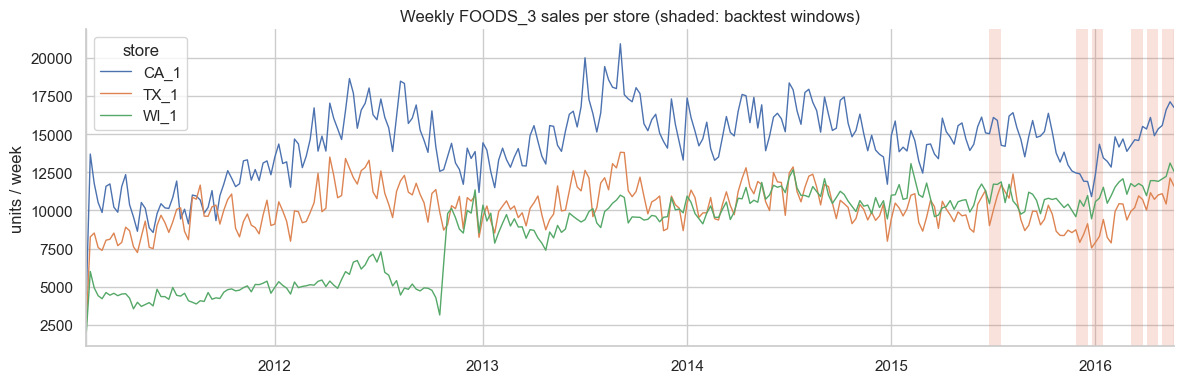

In [7]:
cutoffs = backtest_cutoffs(last_ds=y_df["ds"].max(), horizon=settings.horizon,
                           n_windows=settings.n_windows)
holiday_cutoffs = [pd.Timestamp(c) for c in settings.holiday_cutoffs]
H = pd.Timedelta(days=settings.horizon)
windows = [(c + pd.Timedelta(days=1), c + H) for c in [*holiday_cutoffs, *cutoffs]]

plot_sales_overview(y_df, s_df=s_df, windows=windows)

plt.tight_layout()
plt.show()

Descriptive statistics use only the history up to the first origin, so that no information from
the evaluation windows leaks into the analysis.

In [8]:
history_df = y_df[y_df["ds"] <= cutoffs[0]]
segments_df = adi_cv2_class(y_df=history_df)
started = (history_df["y"] > 0).groupby(history_df["unique_id"]).cummax()
first_sale = history_df[history_df["y"] > 0].groupby("unique_id")["ds"].min()
vol = segments_df["volume"].sort_values(ascending=False)

print(f"Zero days after launch: {(history_df.loc[started, 'y'] == 0).mean():.0%}")
print(f"Series launched after the first day: {(first_sale > y_df.ds.min()).mean():.0%}")
print(f"Volume share of the top 10% series: {vol.head(n=len(vol) // 10).sum() / vol.sum():.0%}")

Zero days after launch: 47%
Series launched after the first day: 72%
Volume share of the top 10% series: 52%


**Reading.** Sales have a strong weekly pattern, a yearly cycle and a near-zero day every Christmas,
when the stores close. The shaded areas are the evaluation windows: the three main origins at the end
of the data and the three holiday origins used in section 9. Each store has its own level and trend, so
store traffic is information a series-level model cannot see by itself, which motivates the past
covariate tried in section 7.

### Demand segments

The Syntetos-Boylan classification splits series by the average interval between sales (ADI) and the
variability of non-zero sales (CV²). It matters because each segment rewards a different point forecast.

In [9]:
segment_summary_df = segments_df.groupby("segment").agg(series=("adi", "size"),
                                                        volume=("volume", "sum"))
segment_summary_df["% series"] = segment_summary_df["series"] / segment_summary_df["series"].sum()
segment_summary_df["% volume"] = segment_summary_df["volume"] / segment_summary_df["volume"].sum()

(segment_summary_df[["series", "% series", "% volume"]]
 .style.format({"% series": "{:.0%}", "% volume": "{:.0%}"}))

,series,% series,% volume
segment,,,
erratic,116,5%,14%
intermittent,1434,58%,28%
lumpy,651,26%,24%
smooth,268,11%,34%


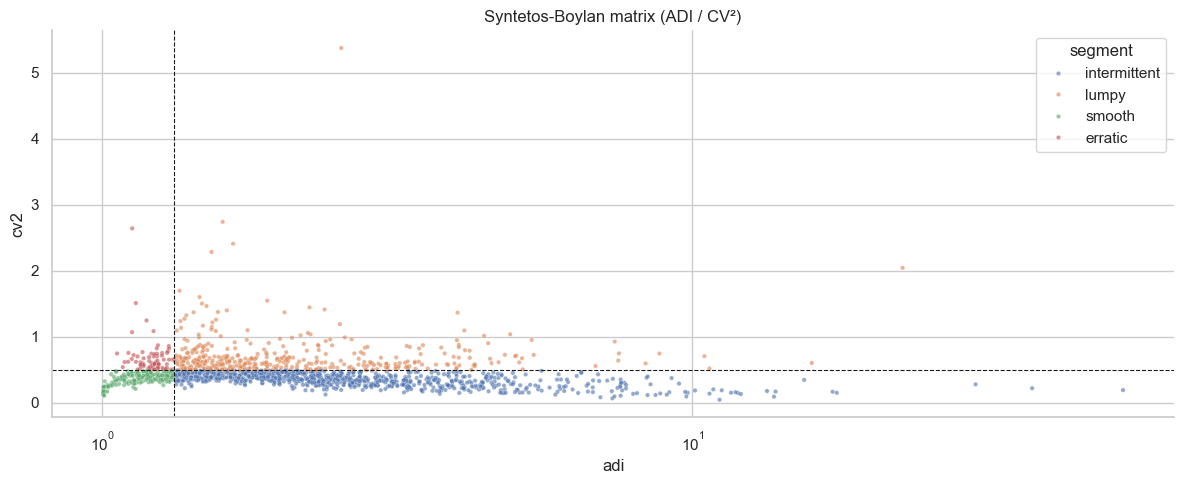

In [10]:
sample_df = segments_df.sample(n=min(1500, len(segments_df)), random_state=0)

fig, ax = plt.subplots(figsize=(FIG_WIDTH, 5))
sns.scatterplot(data=sample_df, x="adi", y="cv2", hue="segment", s=10, alpha=0.6, ax=ax)
ax.axvline(x=1.32, color="k", lw=0.8, ls="--")
ax.axhline(y=0.49, color="k", lw=0.8, ls="--")
ax.set_xscale("log")
ax.set_title("Syntetos-Boylan matrix (ADI / CV²)")

plt.tight_layout()
plt.show()

One example per segment: the series at the 90th percentile of volume within the segment, so that
the examples are representative of the volume that drives the metrics.

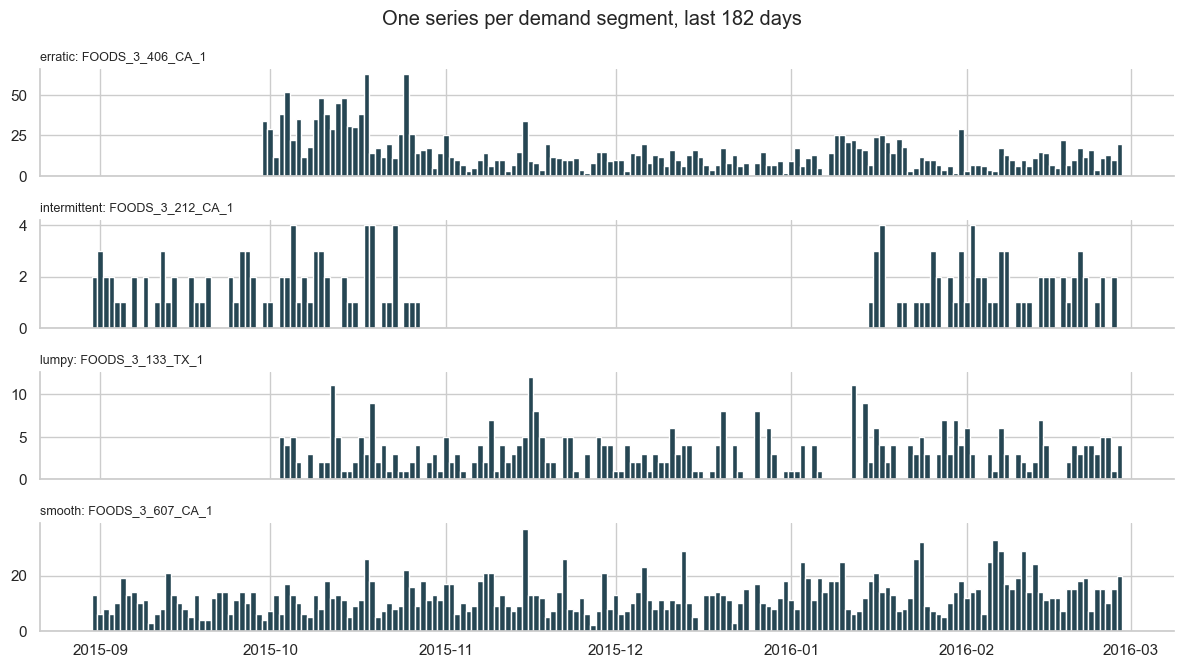

In [11]:
ranked_df = segments_df.sort_values("volume")
examples = pd.Series({s: g.index[int(len(g) * 0.9)] for s, g in ranked_df.groupby("segment")})

plot_segment_examples(y_df=history_df, examples=examples)

plt.tight_layout()
plt.show()

Most series are **intermittent**: many zero days and small quantities, the hardest case for every
model and the one where WMAPE alone misleads (section 4). Volume, however, is concentrated in the
*smooth* and *erratic* series, which therefore weigh most in volume-weighted metrics.

### Prices

Price is the covariate with the most potential, and the most trouble (section 11).

In [12]:
ctx_start = cutoffs[-1] - pd.Timedelta(days=settings.timestral_max_context - 1)
recent_prices_df = x_df[x_df["ds"].between(left=ctx_start, right=cutoffs[-1])]
moves = recent_prices_df.groupby("unique_id")["sell_price"].nunique()
horizon_prices_df = x_df[x_df["ds"].between(left=cutoffs[-1] + pd.Timedelta(days=1), right=cutoffs[-1] + H)]
changes_in_horizon = horizon_prices_df.groupby("unique_id")["sell_price"].nunique() > 1

print(f"Series whose price never moved in the {settings.timestral_max_context} context days: "
      f"{(moves <= 1).mean():.0%}")
print(f"Series with a price change inside the last 28-day window: {changes_in_horizon.mean():.0%}")

Series whose price never moved in the 1024 context days: 41%
Series with a price change inside the last 28-day window: 4%


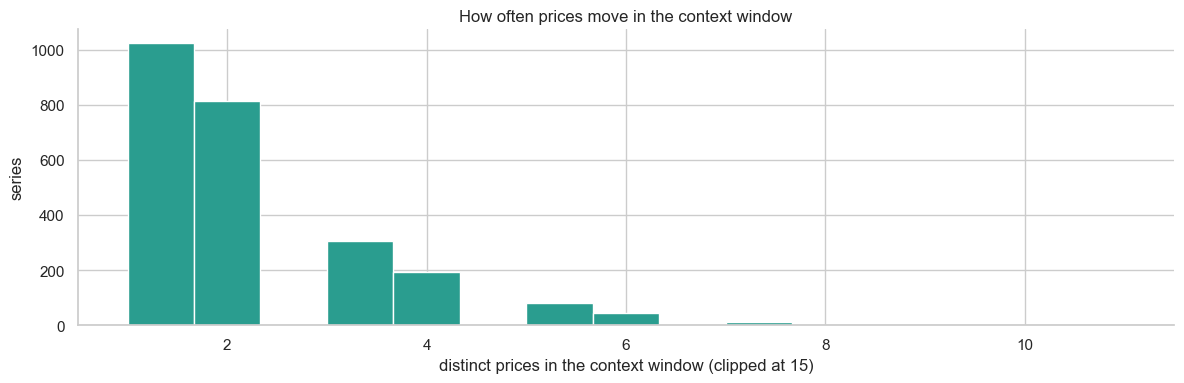

In [13]:
fig, ax = plt.subplots(figsize=(FIG_WIDTH, 4))
moves.clip(upper=15).plot.hist(bins=15, ax=ax, color="#2a9d8f")
ax.set_xlabel("distinct prices in the context window (clipped at 15)")
ax.set_ylabel("series")
ax.set_title("How often prices move in the context window")

plt.tight_layout()
plt.show()

**Reading.** At the last origin 41% of the series have a price that never moved in the 1,024 days
Timestral reads, and only 4% see a price change inside the 28-day window. Price is therefore informative
for a minority of series, and for the flat ones it is worse than useless: section 11 shows how a constant
row interacts with Timestral's per-row normalisation.

## 2. Timestral in a nutshell

The package installs from the official repository and depends only on torch, numpy, safetensors and
huggingface_hub. Weights are downloaded from Hugging Face on first use (111 MB for the 28M). The larger
209M checkpoint is left out of this analysis: with covariates its forecasts stayed unstable even with the
safeguard described in section 11. The whole API is one class and one method:

```python
from timestral import TimestralForecaster

model = TimestralForecaster.from_pretrained("mistralai/Timestral-28M", device="cpu", max_context=1024)
forecast = model.forecast(
    context,                 # (B, V, T) target history, NaN = missing
    prediction_length=28,    # H
    known_covariates=None,   # (B, C, T + H): known over context AND horizon (price, calendar...)
    past_covariates=None,    # (B, P, T): observed over the context only (store traffic...)
)
forecast.quantiles           # torch tensor (B, V, H, 21)
forecast.quantile_levels     # (0.01, 0.05, 0.1, ..., 0.9, 0.95, 0.99)
forecast.median              # (B, V, H)
```

* **B** is the batch of independent series, **V** the target variates forecast *jointly* (attention runs
  across them), **T** the context length, **H** the horizon.
* Two defaults matter: `symmetric_averaging` averages the forecast of the context with the mirrored
  forecast of `-context` (and of negated covariates), and `clip_nonnegative` clips at zero the series whose
  context is never negative.
* `max_context` keeps only the last N steps. 1024 days, almost three years, is enough to see the yearly
  cycle and halves the runtime compared with the full history.

A first call on the best-selling smooth series, passed as a plain `(T,)` array:

In [14]:
model_28m = load_timestral(model_id="mistralai/Timestral-28M", device=settings.device,
                           max_context=settings.timestral_max_context)
uid = segments_df[segments_df.segment == "smooth"].sort_values("volume").index[-1]
one = y_df[(y_df.unique_id == uid) & (y_df.ds <= cutoffs[-1])]["y"].to_numpy()

t0 = time.perf_counter()
fc = model_28m.forecast(context=one, prediction_length=settings.horizon)
elapsed = time.perf_counter() - t0

print(f"{uid}: context {one.shape} -> quantiles {tuple(fc.quantiles.shape)} in {elapsed:.2f}s")
print(f"Quantile levels: {fc.quantile_levels}")

FOODS_3_586_TX_1: context (1913,) -> quantiles (1, 1, 28, 21) in 0.03s
Quantile levels: (0.01, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 0.99)


Each row is a forecast day and each column a quantile level (every fourth of the 21). The spread
between q01 and q99 is the model's uncertainty: for this high-volume item it goes from about half to about
1.6 times the median.

In [15]:
forecast_days = pd.date_range(start=cutoffs[-1] + pd.Timedelta(days=1), periods=settings.horizon).date
levels = [f"q{round(q * 100):02d}" for q in fc.quantile_levels]
quantiles_df = pd.DataFrame(data=fc.quantiles[0, 0].numpy(), index=forecast_days, columns=levels)

quantiles_df.iloc[:, ::4].head().style.format("{:.1f}")

,q01,q20,q40,q60,q80,q99
2016-04-25,25.6,41.0,46.3,50.9,56.8,79.2
2016-04-26,22.4,37.8,43.0,47.4,53.2,74.0
2016-04-27,22.5,38.2,43.2,47.7,53.8,74.8
2016-04-28,22.8,39.1,44.0,48.5,54.6,76.3
2016-04-29,25.1,42.2,47.7,52.7,59.1,83.2


## 3. How the data is passed to Timestral

For the backtest on thousands of series we use the **batched univariate** setup: each series is one batch
element (B) with a single target variate (V = 1). `build_timestral_arrays` turns the long frames into
arrays for one origin, following three rules:

* **Before launch = NaN, not zero.** Before its first sale the item was not on the shelf; zeros would
  teach the model a demand that never existed. After launch a zero is real demand.
* **Known covariates `(B, C, T + H)`** cover the context **and** the horizon: price, SNAP day and event day,
  which are planned in advance, plus sine/cosine of day of week and day of year. Rows that only take
  0/1 values are treated by the model as indicators.
* **Covariates are not forecast**: they condition the target forecast and never read the target.

In [16]:
inp = build_timestral_arrays(y_df, cutoff=cutoffs[-1], horizon=settings.horizon, x_df=x_df)
B, V, T = inp.context.shape

print(f"context: {inp.context.shape}, float32, NaN share (pre-launch) {np.isnan(inp.context).mean():.1%}")
print(f"known_covariates: {inp.known_covariates.shape}, rows {inp.covariate_names}")
print(f"unique_ids: {inp.unique_ids.shape}, e.g. {inp.unique_ids[:3].tolist()}")
print(f"forecast dates: {inp.future_ds[0].date()} -> {inp.future_ds[-1].date()} (H = {len(inp.future_ds)})")

context: (2469, 1, 1913), float32, NaN share (pre-launch) 22.0%
known_covariates: (2469, 7, 1941), rows ('sell_price', 'snap', 'is_event', 'dow_sin', 'dow_cos', 'doy_sin', 'doy_cos')
unique_ids: (2469,), e.g. ['FOODS_3_001_CA_1', 'FOODS_3_001_TX_1', 'FOODS_3_001_WI_1']
forecast dates: 2016-04-25 -> 2016-05-22 (H = 28)


The same arrays seen as a table for one series around the origin: the last 5 context days and the
first 5 horizon days. The target stops at the origin (it is what the model has to fill in), while the
known covariates carry on into the horizon.

In [17]:
def input_table(inputs, unique_id, days=5):
    i = inputs.index_of(unique_id)
    t = inputs.context.shape[-1]
    dates = inputs.context_ds.append(inputs.future_ds)
    rows = {"target": np.append(arr=inputs.context[i, 0], values=[np.nan] * len(inputs.future_ds))}
    rows |= dict(zip(inputs.covariate_names, inputs.known_covariates[i], strict=True))
    return pd.DataFrame(data=rows, index=dates.date).T.round(3).iloc[:, t - days : t + days]


input_table(inputs=inp, unique_id=uid)

,2016-04-20,2016-04-21,2016-04-22,2016-04-23,2016-04-24,2016-04-25,2016-04-26,2016-04-27,2016-04-28,2016-04-29
target,45.000,59.000,50.000,56.000,58.000,NaN,NaN,NaN,NaN,NaN
sell_price,1.680,1.680,1.680,1.680,1.680,1.680,1.680,1.680,1.680,1.680
snap,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
is_event,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
dow_sin,0.975,0.434,-0.434,-0.975,-0.782,0.000,0.782,0.975,0.434,-0.434
dow_cos,-0.223,-0.901,-0.901,-0.223,0.623,1.000,0.623,-0.223,-0.901,-0.901
doy_sin,0.943,0.937,0.931,0.925,0.918,0.911,0.904,0.896,0.889,0.881
doy_cos,-0.332,-0.348,-0.364,-0.380,-0.396,-0.412,-0.428,-0.443,-0.458,-0.474


The most recently launched item shows the pre-launch rule at work: everything before its first sale
is passed as missing.

In [18]:
late = first_sale.sort_values().index[-1]
n_missing = np.isnan(inp.context[inp.index_of(late), 0]).sum()

print(f"{late} first sold on {first_sale[late].date()}: its first {n_missing} of {T} context steps "
      "are NaN (not on the shelf yet)")

FOODS_3_595_CA_1 first sold on 2016-02-17: its first 1845 of 1913 context steps are NaN (not on the shelf yet)


The same arrays as a picture: the last 120 context days of the target and every known covariate row,
with the forecast horizon shaded. Price changes rarely, SNAP and events are sparse 0/1 indicators,
and the calendar rows carry the weekly and yearly cycle into the horizon.

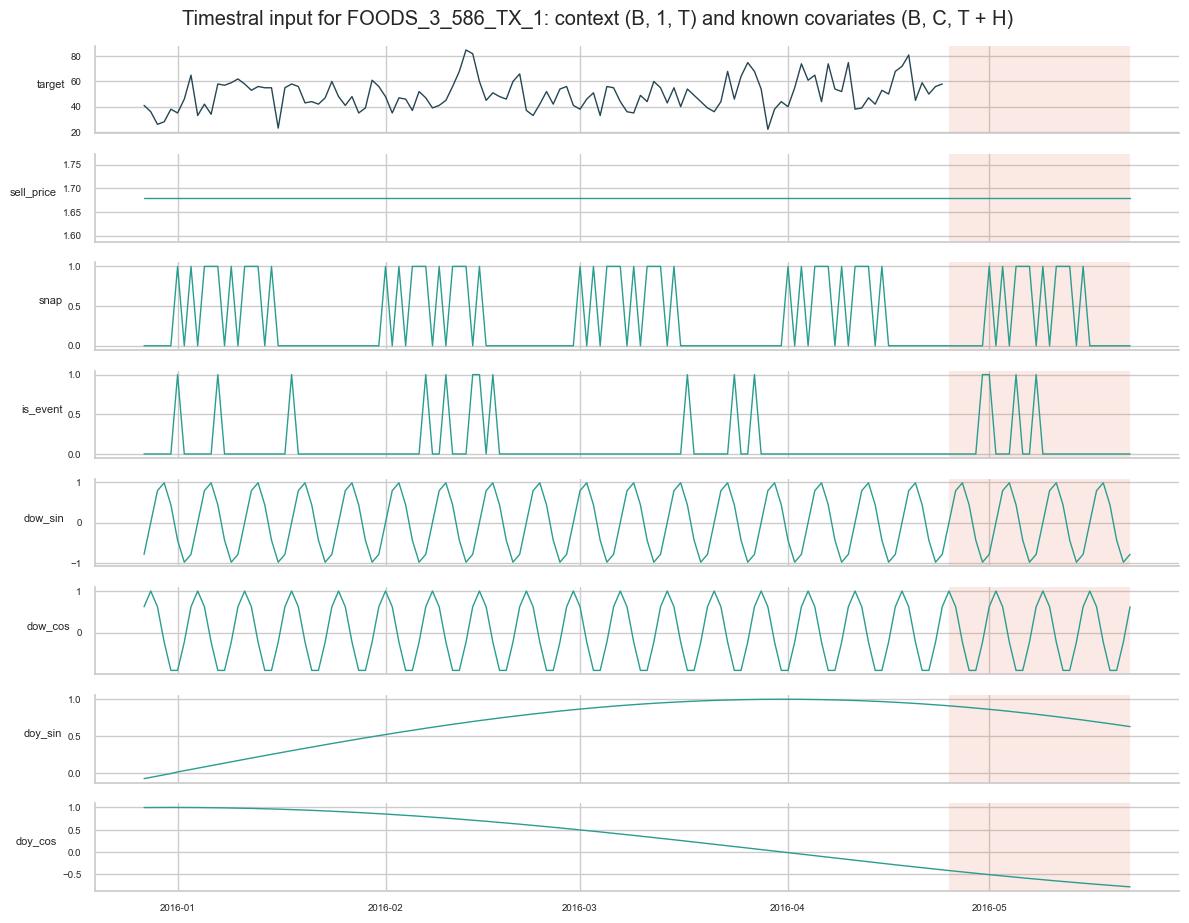

In [19]:
plot_timestral_inputs(inputs=inp, unique_id=uid)

plt.tight_layout()
plt.show()

### The Timestral configurations of the benchmark

Beyond the history-only and known-covariate runs, two extensions use the other input types of the API:

* **`+past`**: the known covariates plus a **past-only covariate**, the daily department total of the
  series' store `(B, 1, T)`. It carries store traffic, closures and local shocks without leaking the
  future.
* **`-mv` (multivariate)**: items of the same store forecast **jointly** as variates of one batch element,
  `(G, V, T)` with V = 4. Groups are formed by clustering the weekly sales of the last year (average linkage
  on 1 - correlation, consecutive leaves of the dendrogram). Covariates must be shared by the whole group,
  so price is dropped and only store-level rows remain (SNAP, events, calendar, store total).

One row per Timestral configuration, with the inputs it receives: the known covariates, whether the
store total is added as a past covariate, how many series share a batch element, and the two safeguards.

In [20]:
variants = {v.alias: v for v in timestral_variants(settings)}

variants_df = pd.DataFrame([v.__dict__ for v in variants.values()]).set_index("alias")

variants_df

,model_id,known_covariates,past_covariates,group_size,symmetric_averaging,mask_constant_price
alias,,,,,,
Timestral-28M,mistralai/Timestral-28M,(),False,1,True,False
Timestral-28M+cov,mistralai/Timestral-28M,"(sell_price, snap, is_event)",False,1,True,True
Timestral-28M+cov+past,mistralai/Timestral-28M,"(sell_price, snap, is_event)",True,1,True,True
Timestral-28M-mv,mistralai/Timestral-28M,"(snap, is_event)",True,4,True,False


The shapes actually passed to the model at the last origin. The multivariate run needs two calls,
because groups of 4 do not divide every store exactly: the remainder forms smaller groups.

In [21]:
past_df = store_totals(y_df, s_df=s_df)
stores = store_of(s_df)

for alias in ("Timestral-28M+cov+past", "Timestral-28M-mv"):
    parts = prepare_inputs(variant=variants[alias], y_df=y_df, cutoff=cutoffs[-1], horizon=settings.horizon,
                           x_df=x_df, past_df=past_df, store_of=stores,
                           context_window=settings.timestral_max_context)
    for p in parts:
        print(f"{alias}: context {p.context.shape}, known {p.known_covariates.shape}, "
              f"past {p.past_covariates.shape}")

Timestral-28M+cov+past: context (2469, 1, 1913), known (2469, 7, 1941), past (2469, 1, 1913)


Timestral-28M-mv: context (615, 4, 1913), known (615, 6, 1941), past (615, 1, 1913)
Timestral-28M-mv: context (3, 3, 1913), known (3, 6, 1941), past (3, 1, 1913)


The multivariate group of the example item, plotted with the same weekly profiles the clustering
compares: these items are grouped because their weekly sales are among the most correlated in the store.

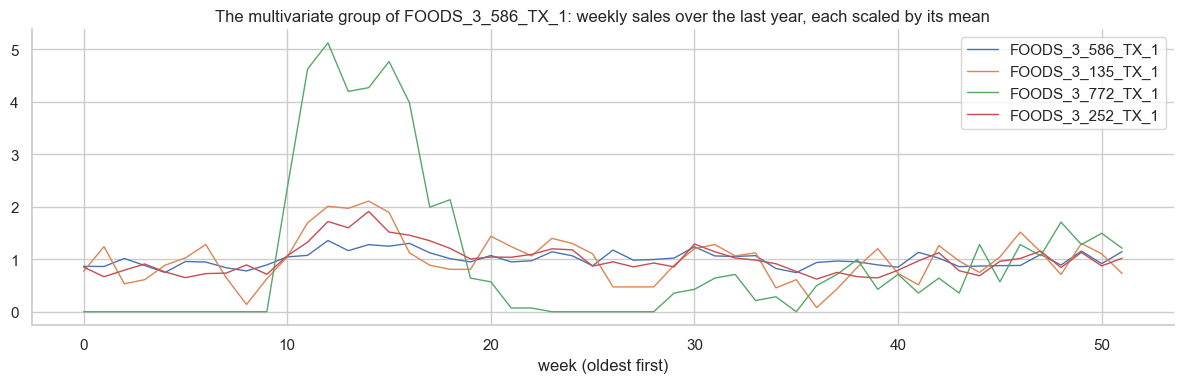

In [22]:
groups = affinity_groups(inputs=inp, store_of=stores, size=settings.timestral_group_size)
group = next(g for g in groups if uid in inp.unique_ids[g])
weekly_df = pd.DataFrame(data=weekly_profiles(context=inp.context[group]).T, columns=inp.unique_ids[group])

ax = (weekly_df / weekly_df.mean()).plot(figsize=(FIG_WIDTH, 4), lw=1)
ax.set_xlabel("week (oldest first)")
ax.set_title(f"The multivariate group of {uid}: weekly sales over the last year, each scaled by its mean")

plt.tight_layout()
plt.show()

## 4. Protocol and metrics

* **3 consecutive origins**, each followed by 28 days to forecast (the last 12 weeks of M5). Every model
  uses the same origins and sees only data up to the origin.
* **All series** are evaluated; when a model produces no forecast (a series never sold before the
  origin) the forecast is 0, as it would be in production. Negative forecasts are clipped at 0.
* Metrics are computed on the aggregated portfolio:

$$\text{WMAPE} = \frac{\sum |F - A|}{\sum A} \qquad \text{Bias} = \frac{\sum (F - A)}{\sum A} \qquad \text{Score} = \text{WMAPE} + |\text{Bias}|$$

The ranking criterion is the **mean score over the origins**: stricter than the overall score, where
biases of opposite sign in different origins cancel out. **FVA** (Forecast Value Added) is the relative
score reduction versus the 28-day moving average.

WMAPE alone **rewards under-forecasting** on intermittent series, because the forecast that minimises it
is the median. A series with two orders in eight days shows why:

In [23]:
act = np.array([0, 0, 10, 0, 0, 0, 12, 0.0])
candidates = {"always zero (= median)": np.zeros(8), "mean": np.full(shape=8, fill_value=act.mean())}

for name, f in candidates.items():
    print(f"{name}: WMAPE {wmape(y=act, y_hat=f):.0%}, bias {bias(y=act, y_hat=f):+.0%}, "
          f"score {score(y=act, y_hat=f):.0%}")

always zero (= median): WMAPE 100%, bias -100%, score 200%
mean: WMAPE 150%, bias +0%, score 150%


Timestral is probabilistic, so it gets two point forecasts: the **median** (q50) and the **mean**,
approximated as the average of the 21 quantiles (columns ending in `-mean`). We also report the **WQL**,
the scaled pinball loss used in GIFT-Eval, and the **coverage** of the q10–q90 interval, nominally 80%.

## 5. Backtest of every model

In [24]:
t0 = time.perf_counter()
merged_df, timings = run_benchmark(settings, data=data)
merged_df = add_ensembles(df=merged_df)

print(f"{len(merged_df):,} rows in {time.perf_counter() - t0:.0f}s (from cache when already computed)")

207,396 rows in 2s (from cache when already computed)


`merged_df` has one row per series, forecast day and origin: the actual `y` next to the forecast of every
model (three shown here). Timestral contributes several columns per run: the median, the `-mean` and the
21 quantiles.

In [25]:
TS = [v.alias for v in timestral_variants(settings)]
BASE = [f"MA{settings.moving_average_window}", "Naive", "SeasonalNaive", "CrostonSBA"]
STAT = ["AutoARIMA", "AutoETS", "AutoCES"]
LGBM = [v.alias for v in LGBM_VARIANTS]
ENS = list(ENSEMBLES)
MODELS = BASE + STAT + LGBM + TS + [f"{a}-mean" for a in TS] + ENS

merged_df[["unique_id", "ds", "cutoff", "y", "Timestral-28M+cov-mean", "LightGBM-norm", "AutoARIMA"]].head()

,unique_id,ds,cutoff,y,Timestral-28M+cov-mean,LightGBM-norm,AutoARIMA
0,FOODS_3_001_CA_1,2016-02-29,2016-02-28,0.0,0.618306,0.537050,0.695620
1,FOODS_3_002_CA_1,2016-02-29,2016-02-28,6.0,3.240730,2.698693,3.382762
2,FOODS_3_003_CA_1,2016-02-29,2016-02-28,0.0,0.001462,0.002383,0.000000
3,FOODS_3_004_CA_1,2016-02-29,2016-02-28,0.0,0.972148,0.899910,1.001668
4,FOODS_3_005_CA_1,2016-02-29,2016-02-28,0.0,0.586599,0.488639,0.532366


## 6. Results

In [26]:
scores_df = fold_table(df=merged_df, models=MODELS, metric="score")
fva = forecast_value_added(table=scores_df, reference=f"MA{settings.moving_average_window}")
overall_df = evaluate(df=merged_df, models=MODELS).set_index("model")
results_df = pd.concat([overall_df[["wmape", "bias"]].add_suffix(" (overall)"),
                        scores_df.rename(columns={"mean": "mean score per origin"}), fva], axis=1)
results_df = results_df.sort_values("mean score per origin")

(results_df.style.format("{:.1%}").format(formatter="{:+.1%}", subset=["bias (overall)"])
 .background_gradient(cmap="RdYlGn_r", subset=["mean score per origin"]))

,wmape (overall),bias (overall),2016-02-28,2016-03-27,2016-04-24,mean score per origin,FVA vs MA28
model,,,,,,,
"Ens(TS+cov, LGBM-norm, ETS)",62.4%,+0.7%,64.9%,66.8%,62.0%,64.6%,5.8%
"Ens(TS+cov, LGBM-norm, ARIMA)",62.8%,+0.6%,65.6%,66.7%,62.5%,64.9%,5.4%
"Ens(TS+cov, LGBM-norm)",62.9%,+1.6%,66.7%,67.1%,61.4%,65.1%,5.1%
Timestral-28M+cov-mean,63.5%,+1.2%,66.6%,67.3%,61.6%,65.2%,4.9%
Timestral-28M+cov+past-mean,63.5%,+1.6%,66.9%,67.6%,61.1%,65.2%,4.9%
Timestral-28M-mv-mean,63.5%,+1.8%,66.9%,67.9%,61.3%,65.4%,4.6%
LightGBM-norm,63.7%,+2.0%,68.2%,68.3%,62.5%,66.3%,3.3%
Timestral-28M-mean,63.6%,+2.8%,68.0%,70.6%,60.9%,66.5%,3.0%
AutoETS,63.5%,-1.2%,68.5%,69.1%,64.9%,67.5%,1.6%


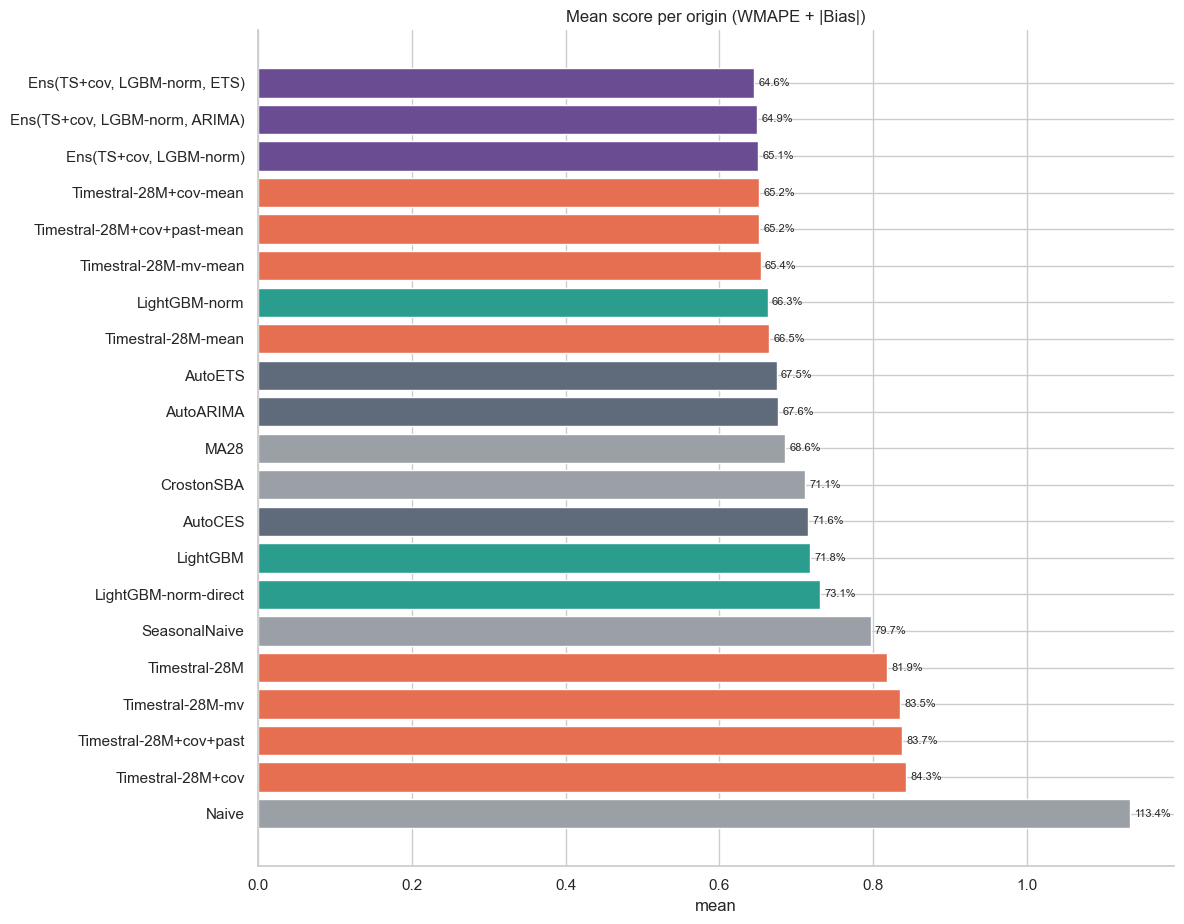

In [27]:
plot_score_bars(summary=scores_df[["mean"]], title="Mean score per origin (WMAPE + |Bias|)", metric="mean")

plt.tight_layout()
plt.show()

The same models on the WMAPE / bias plane (ensembles left out): the Timestral medians sit at low WMAPE
and large negative bias, the means close to zero bias.

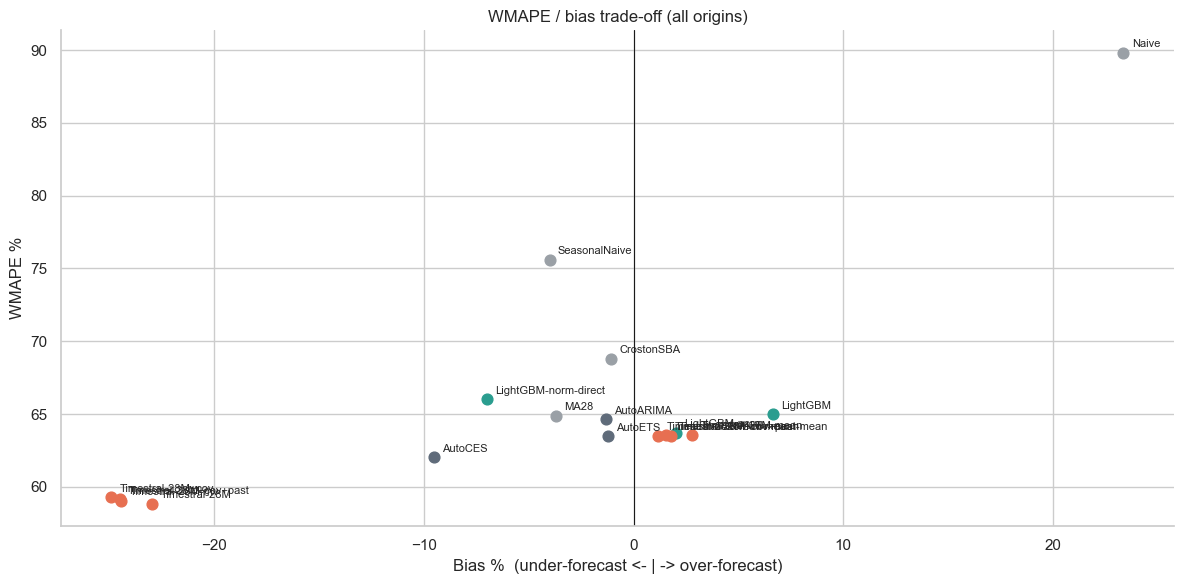

In [28]:
plot_wmape_bias(summary=overall_df.drop(index=ENS))

plt.tight_layout()
plt.show()

**Reading.**

* **The point forecast matters more than the model.** Every Timestral median (rows without `-mean`) has
  the lowest WMAPE of the table (58.8–59.3%) and the worst bias (−23% to −25%): the median of an
  intermittent series is often zero. The mean of the 21 quantiles removes the bias and moves Timestral
  from the bottom to the top. AutoCES shows the same trap from the statistical side: lowest WMAPE among
  the benchmarks, −9.5% bias.
* **Zero-shot Timestral beats every benchmark.** Timestral-28M+cov (mean) scores 65.2% against 66.3% for
  the best LightGBM and 67.5–67.6% for AutoETS and AutoARIMA, an FVA of +4.9% over the moving average.
  The history-only 28M is already level with LightGBM-norm (66.5%).
* **The lead is consistent but not large.** Timestral-28M+cov is ahead of LightGBM-norm on all three
  origins, by 0.9–1.6 points; the spread between origins (61–67%) is larger than the gap between the best
  models.

### Probabilistic quality of Timestral

In [29]:
y = merged_df["y"].to_numpy()
rows = []
for alias in TS:
    qcols = [c for c in merged_df.columns if c.startswith(f"{alias}_q")]
    levels = [int(c[-2:]) / 100 for c in qcols]
    rows.append({"model": alias,
                 "WQL": weighted_quantile_loss(y, quantiles=merged_df[qcols].to_numpy(), levels=levels),
                 "q10-q90 coverage": coverage(y, lower=merged_df[quantile_column(alias, level=0.1)],
                                              upper=merged_df[quantile_column(alias, level=0.9)]),
                 "median bias": bias(y, y_hat=merged_df[alias].to_numpy()),
                 "mean bias": bias(y, y_hat=merged_df[f"{alias}-mean"].to_numpy()),
                 "max mean forecast": merged_df[f"{alias}-mean"].max()})

proba_df = pd.DataFrame(rows).set_index("model")

(proba_df.style.format(formatter="{:.3f}", subset=["WQL"])
 .format(formatter="{:.0%}", subset=["q10-q90 coverage"])
 .format(formatter="{:+.1%}", subset=["median bias", "mean bias"])
 .format(formatter="{:.0f}", subset=["max mean forecast"]))

,WQL,q10-q90 coverage,median bias,mean bias,max mean forecast
model,,,,,
Timestral-28M,0.408,85%,-23.0%,+2.8%,84
Timestral-28M+cov,0.410,83%,-24.9%,+1.2%,83
Timestral-28M+cov+past,0.409,83%,-24.5%,+1.6%,87
Timestral-28M-mv,0.408,84%,-24.4%,+1.8%,82


**Reading.** The distribution is well calibrated: 83–85% of the actuals fall in the nominal 80%
q10–q90 interval (slightly wide), and the WQL is the same for every variant (0.408–0.410), so covariates,
the past covariate and the multivariate grouping do not change the quality of the distribution, only the
level of the centre. The gap between median bias (about −24%) and mean bias (+1% to +3%) quantifies how
skewed the predictive distributions are on this data. With the constant-price mask the largest mean
forecast stays below 90 units for every variant: no more blow-ups.

### By demand segment

Segments are computed from data available at the first origin only.

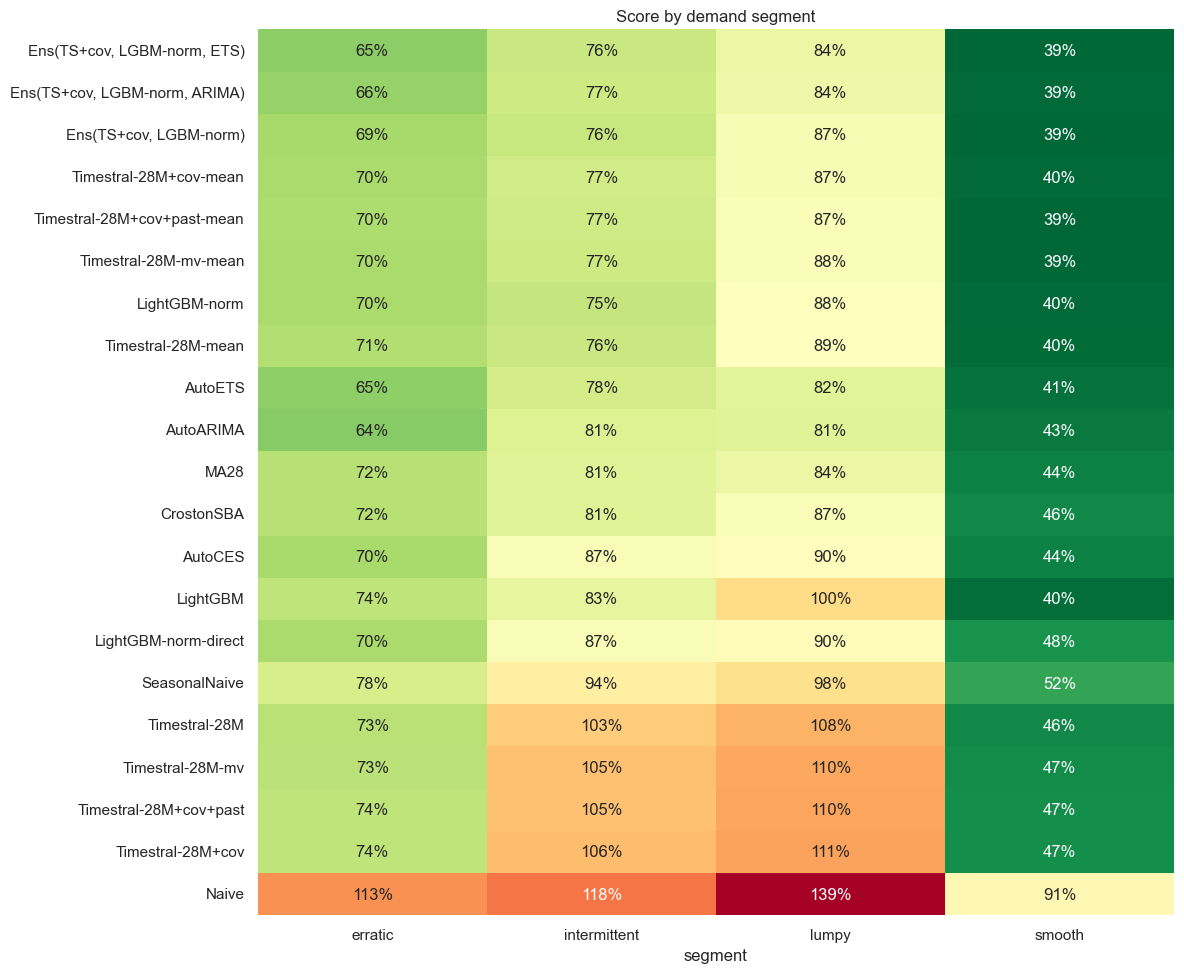

In [30]:
merged_df["segment"] = merged_df["unique_id"].map(segments_df["segment"]).fillna("no sales")
segment_scores_df = (evaluate(df=merged_df, models=MODELS, by="segment")
           .pivot(index="model", columns="segment", values="score"))

plot_heatmap(table=segment_scores_df.loc[results_df.index], xlabel="segment",
             title="Score by demand segment")

plt.tight_layout()
plt.show()

Share of the evaluated volume in each segment, to weigh the heatmap: smooth and intermittent series
carry two thirds of the units.

In [31]:
volume_share = merged_df.groupby("segment")["y"].sum() / merged_df["y"].sum()

volume_share.to_frame(name="volume share").T.style.format("{:.0%}")

segment,erratic,intermittent,lumpy,smooth
volume share,10%,34%,23%,33%


**Reading.**

* **Smooth** (34% of the volume) and **intermittent** (28%): Timestral (mean) and LightGBM-norm lead,
  with scores around 0.39–0.40 and 0.75–0.77, against 0.41–0.43 and 0.78–0.81 for ETS and ARIMA.
* **Erratic** and **lumpy**: the statistical models win (AutoARIMA 0.64 on erratic, AutoETS / AutoARIMA
  0.82 on lumpy, against about 0.70 and 0.87 for Timestral). On series with rare, large spikes the
  conservative level of an exponential smoothing pays off.
* The medians collapse on intermittent and lumpy series (scores above 1.0) and are competitive only on
  smooth ones, which confirms that the bias comes from zero-inflated distributions.

Different winners on different segments are the premise of the ensembles in section 8.

### Compute time (CPU, 3 origins, all series)

In [32]:
timings.to_frame(name="seconds").sort_values("seconds").style.format("{:.0f}")

,seconds
baselines,12
Timestral-28M,39
ets,63
LightGBM,67
LightGBM-norm,146
Timestral-28M-mv,255
Timestral-28M+cov,701
Timestral-28M+cov+past,788
LightGBM-norm-direct,809
arima,2712


### Example forecasts

The 90th-percentile series by volume of each segment, last origin.

In [33]:
last_origin_df = merged_df[merged_df["cutoff"] == cutoffs[-1]]
history_last_df, _ = split_at(df=y_df, cutoff=cutoffs[-1], horizon=settings.horizon)
best_ts = "Timestral-28M+cov"


def plot_example(segment):
    example = examples[segment]
    example_df = last_origin_df[last_origin_df.unique_id == example].sort_values("ds")
    ax = plot_series_forecast(history=history_last_df, window=last_origin_df, alias=best_ts,
                              unique_id=example)
    ax.plot(example_df["ds"], example_df["LightGBM-norm"], color="#2a9d8f", lw=1.2,
            label="LightGBM-norm")
    ax.plot(example_df["ds"], example_df["AutoARIMA"], color="#5f6b7a", lw=1.2, ls="--",
            label="AutoARIMA")
    ax.legend(loc="upper left", fontsize=8, ncol=8)
    ax.set_title(f"{example} ({segment}) - {best_ts}")
    plt.tight_layout()
    plt.show()

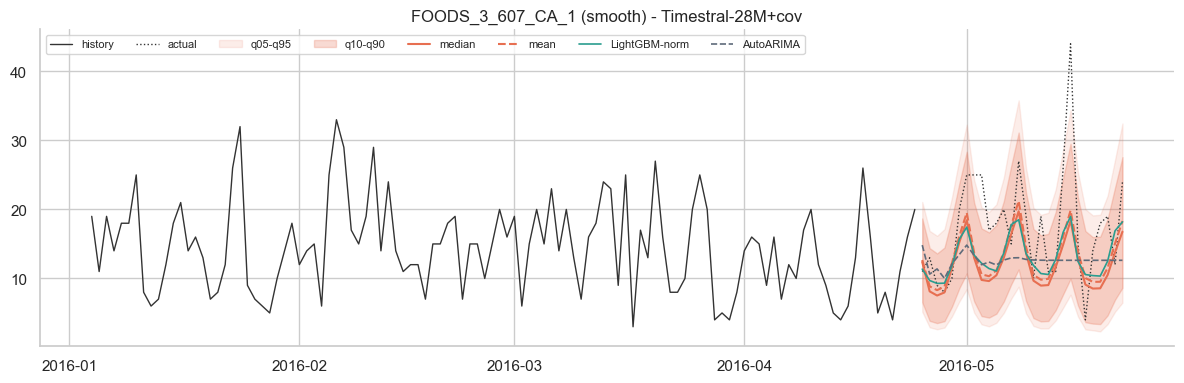

In [34]:
plot_example(segment="smooth")

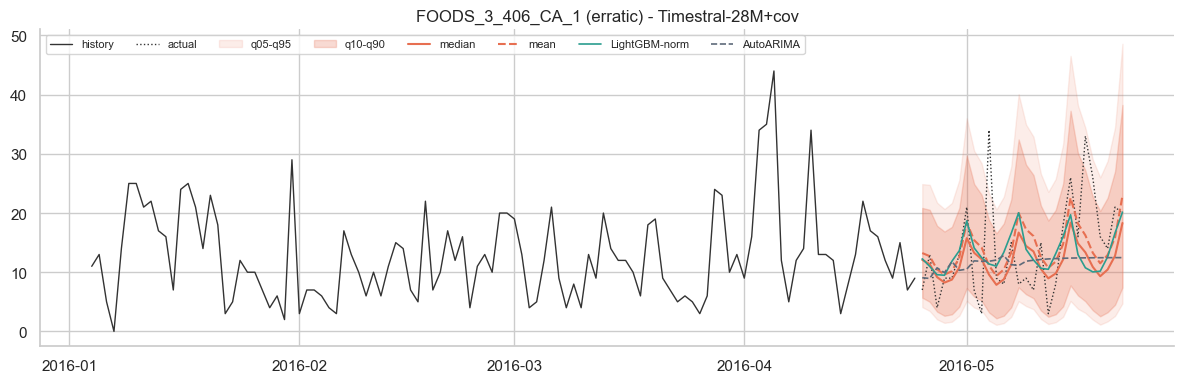

In [35]:
plot_example(segment="erratic")

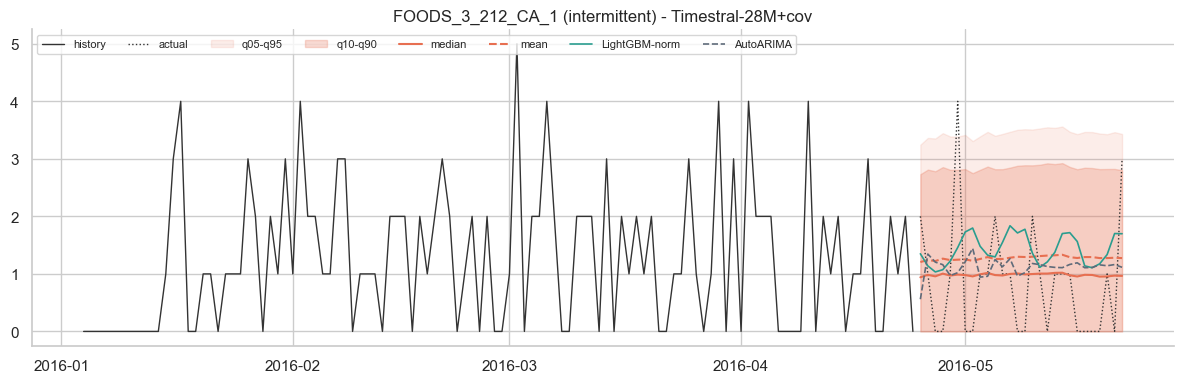

In [36]:
plot_example(segment="intermittent")

## 7. Timestral extensions: past covariate and multivariate

In [37]:
ext = ["Timestral-28M-mean", "Timestral-28M+cov-mean", "Timestral-28M+cov+past-mean",
       "Timestral-28M-mv-mean", "LightGBM-norm"]
extensions_df = results_df.loc[ext, ["wmape (overall)", "bias (overall)", "mean score per origin"]]
extensions_df["seconds"] = [timings.get(a.removesuffix("-mean")) for a in ext]

(extensions_df.style.format(formatter="{:.1%}", subset=["wmape (overall)", "mean score per origin"])
 .format(formatter="{:+.1%}", subset=["bias (overall)"])
 .format(formatter="{:.0f}", subset=["seconds"]))

,wmape (overall),bias (overall),mean score per origin,seconds
model,,,,
Timestral-28M-mean,63.6%,+2.8%,66.5%,39
Timestral-28M+cov-mean,63.5%,+1.2%,65.2%,701
Timestral-28M+cov+past-mean,63.5%,+1.6%,65.2%,788
Timestral-28M-mv-mean,63.5%,+1.8%,65.4%,255
LightGBM-norm,63.7%,+2.0%,66.3%,146


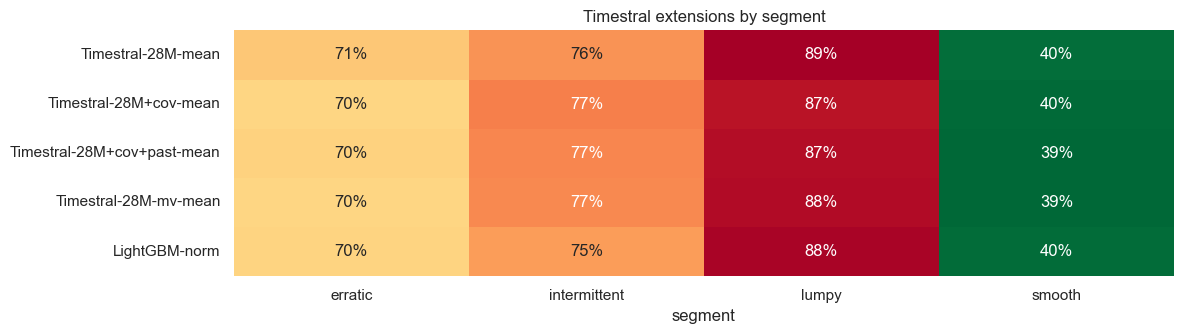

In [38]:
plot_heatmap(table=segment_scores_df.loc[ext], xlabel="segment",
             title="Timestral extensions by segment")

plt.tight_layout()
plt.show()

**Reading.**

* **Past covariate (store total): no gain.** Same score as the known-covariate run (65.2%), slightly
  more bias, 12% more time. The store total mostly repeats the information already in the series' own
  history and calendar.
* **Multivariate: same accuracy, a third of the cost.** 65.4% against 65.2%, without item prices, in
  255 s instead of 701 s, because four series share one batch element. Joint forecasting of affine
  items does not uncover cross-series signal that the univariate model misses, but it is the cheapest
  way to add store-level covariates.
* None of the extensions changes the picture by segment.

## 8. Ensembles

Section 6 shows that the families win on different segments. An **equal-weight average** of models with
different strengths is the cheapest way to exploit that: there are no weights to fit, so it cannot overfit
the backtest. Ensembles help when the members' errors are not too correlated, which the first table checks
(correlation of the daily errors `F - A`).

In [39]:
members = sorted({m for ms in ENSEMBLES.values() for m in ms})
errors_df = merged_df[members].sub(other=merged_df["y"], axis=0)

errors_df.corr().style.format("{:.2f}").background_gradient(cmap="Blues")

,AutoARIMA,AutoETS,LightGBM-norm,Timestral-28M+cov-mean
AutoARIMA,1.00,0.90,0.89,0.92
AutoETS,0.90,1.00,0.88,0.88
LightGBM-norm,0.89,0.88,1.00,0.93
Timestral-28M+cov-mean,0.92,0.88,0.93,1.00


The ensembles next to their members, sorted by mean score per origin.

In [40]:
columns = ["wmape (overall)", "bias (overall)", "mean score per origin",
           f"FVA vs MA{settings.moving_average_window}"]
ensembles_df = results_df.loc[ENS + members, columns].sort_values("mean score per origin")

ensembles_df.style.format("{:.1%}").format(formatter="{:+.1%}", subset=["bias (overall)"])

,wmape (overall),bias (overall),mean score per origin,FVA vs MA28
model,,,,
"Ens(TS+cov, LGBM-norm, ETS)",62.4%,+0.7%,64.6%,5.8%
"Ens(TS+cov, LGBM-norm, ARIMA)",62.8%,+0.6%,64.9%,5.4%
"Ens(TS+cov, LGBM-norm)",62.9%,+1.6%,65.1%,5.1%
Timestral-28M+cov-mean,63.5%,+1.2%,65.2%,4.9%
LightGBM-norm,63.7%,+2.0%,66.3%,3.3%
AutoETS,63.5%,-1.2%,67.5%,1.6%
AutoARIMA,64.6%,-1.3%,67.6%,1.4%


**Reading.** The daily errors of the members are 88–93% correlated: they all miss the same spikes.
The ensembles still give the best score of the benchmark (64.6% with AutoETS, FVA +5.8%), but the gain
over Timestral-28M+cov alone is only 0.6 points. AutoETS is the best third member because its errors are
the least correlated with the others (0.88) and its negative bias offsets the positive bias of Timestral
and LightGBM. The equal-weight average has no parameter to tune, so this gain is not an artefact of the
backtest.

## 9. Holiday origins

The three main origins cover February–May 2016, a quiet period. Three more origins put the forecast
window across US holidays: **Independence Day** (origin 2015-06-21), **Thanksgiving** (2015-11-22) and
**Christmas and New Year** (2015-12-20), when stores close for a day and shopping patterns shift. Only the
models that matter for the conclusions are re-run (`settings.holiday_jobs`).

In [41]:
holiday_merged_df, h_timings = run_holiday_benchmark(settings, data=data)
holiday_merged_df = add_ensembles(df=holiday_merged_df)
H_MODELS = [m for m in MODELS if m in holiday_merged_df.columns and m not in TS]

holiday_scores_df = fold_table(df=holiday_merged_df, models=H_MODELS, metric="score")
holiday_overall_df = evaluate(df=holiday_merged_df, models=H_MODELS).set_index("model")
holiday_compare_df = pd.concat([holiday_scores_df.rename(columns={"mean": "holidays mean"}),
                                holiday_overall_df[["wmape", "bias"]].add_prefix("holidays "),
                                scores_df.loc[H_MODELS, "mean"].rename("main origins mean")], axis=1)

(holiday_compare_df.sort_values("holidays mean").style.format("{:.1%}")
 .format(formatter="{:+.1%}", subset=["holidays bias"])
 .background_gradient(cmap="RdYlGn_r", subset=["holidays mean"]))

,2015-06-21,2015-11-22,2015-12-20,holidays mean,holidays wmape,holidays bias,main origins mean
model,,,,,,,
AutoETS,66.6%,78.4%,76.7%,73.9%,71.3%,+2.1%,67.5%
AutoCES,70.4%,73.6%,78.0%,74.0%,70.7%,-2.5%,71.6%
MA28,71.4%,75.5%,76.5%,74.5%,72.5%,-0.2%,68.6%
AutoARIMA,70.2%,80.3%,78.6%,76.4%,72.0%,+4.0%,67.6%
"Ens(TS+cov, LGBM-norm, ETS)",72.5%,84.2%,77.3%,78.0%,70.9%,+6.7%,64.6%
"Ens(TS+cov, LGBM-norm, ARIMA)",73.7%,84.9%,78.1%,78.9%,71.2%,+7.4%,64.9%
"Ens(TS+cov, LGBM-norm)",76.3%,88.1%,78.6%,81.0%,71.7%,+9.0%,65.1%
Timestral-28M+cov-mean,74.8%,85.0%,83.8%,81.2%,71.6%,+9.2%,65.2%
Timestral-28M-mv-mean,75.5%,86.5%,83.3%,81.8%,71.8%,+9.6%,65.4%


Total daily units of the Christmas / New Year window, actual against four forecasts: the forecasts
repeat the usual weekly shape, while the actuals spike before the holidays and drop to zero on
Christmas Day.

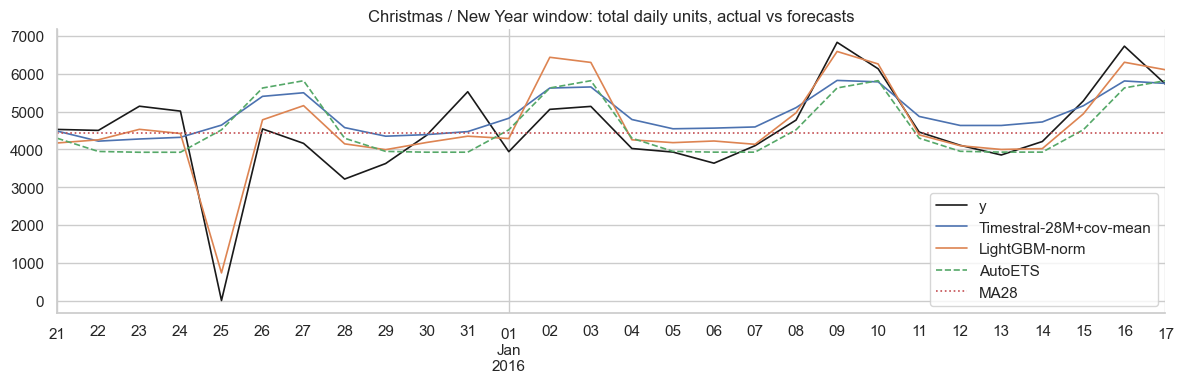

In [42]:
xmas_df = holiday_merged_df[holiday_merged_df["cutoff"] == holiday_cutoffs[-1]]
shown = ["y", "Timestral-28M+cov-mean", "LightGBM-norm", "AutoETS", "MA28"]
xmas_daily_df = xmas_df.groupby("ds")[shown].sum()

ax = xmas_daily_df.plot(figsize=(FIG_WIDTH, 4), lw=1.2, style=["k-", "-", "-", "--", ":"])
ax.set_xlabel("")
ax.set_title("Christmas / New Year window: total daily units, actual vs forecasts")

plt.tight_layout()
plt.show()

**Reading. The ranking does not survive the holidays.**

* **The simple models win**: AutoETS 73.9%, AutoCES 74.0%, moving average 74.5%. The best ensemble scores
  78.0%, Timestral-28M+cov (mean) 81.2%, LightGBM-norm 82.0%.
* **Accuracy is not the problem, bias is.** The holiday WMAPE is almost the same for every serious model
  (70.7–72.8%; the ensemble has the best, 70.9%). Timestral and LightGBM over-forecast by about 9–10%,
  AutoETS by 2% and the moving average not at all.
* **Where the bias comes from.** Timestral and LightGBM project the usual weekend peaks, but the weekends
  around Thanksgiving, Christmas and Independence Day sold less than usual. The pre-holiday peaks
  (25 November, 23–24 and 31 December, 3 July) are missed by every model.
* **Christmas Day.** Stores are closed (2 units sold in total). LightGBM, which learned from previous Christmas Days,
  forecasts 732 units; Timestral+cov about 4,640, because `is_event` is a single 0/1 row that cannot tell a
  closure from any other event.
* The result holds without Christmas Day and at the weekly level.

Holiday windows need either a holiday-specific covariate or a bias correction; zero-shot Timestral does
not handle them on its own.

## 10. Evaluation at the level of the decision

A replenishment order rarely covers a single day: it covers a week, or the supplier lead time. What the
planner experiences is the error on the **sum** of the forecasts over that period, where daily errors of
opposite sign partly cancel. Here every series is aggregated into weekly buckets and into the full 28-day
window before computing the same score.

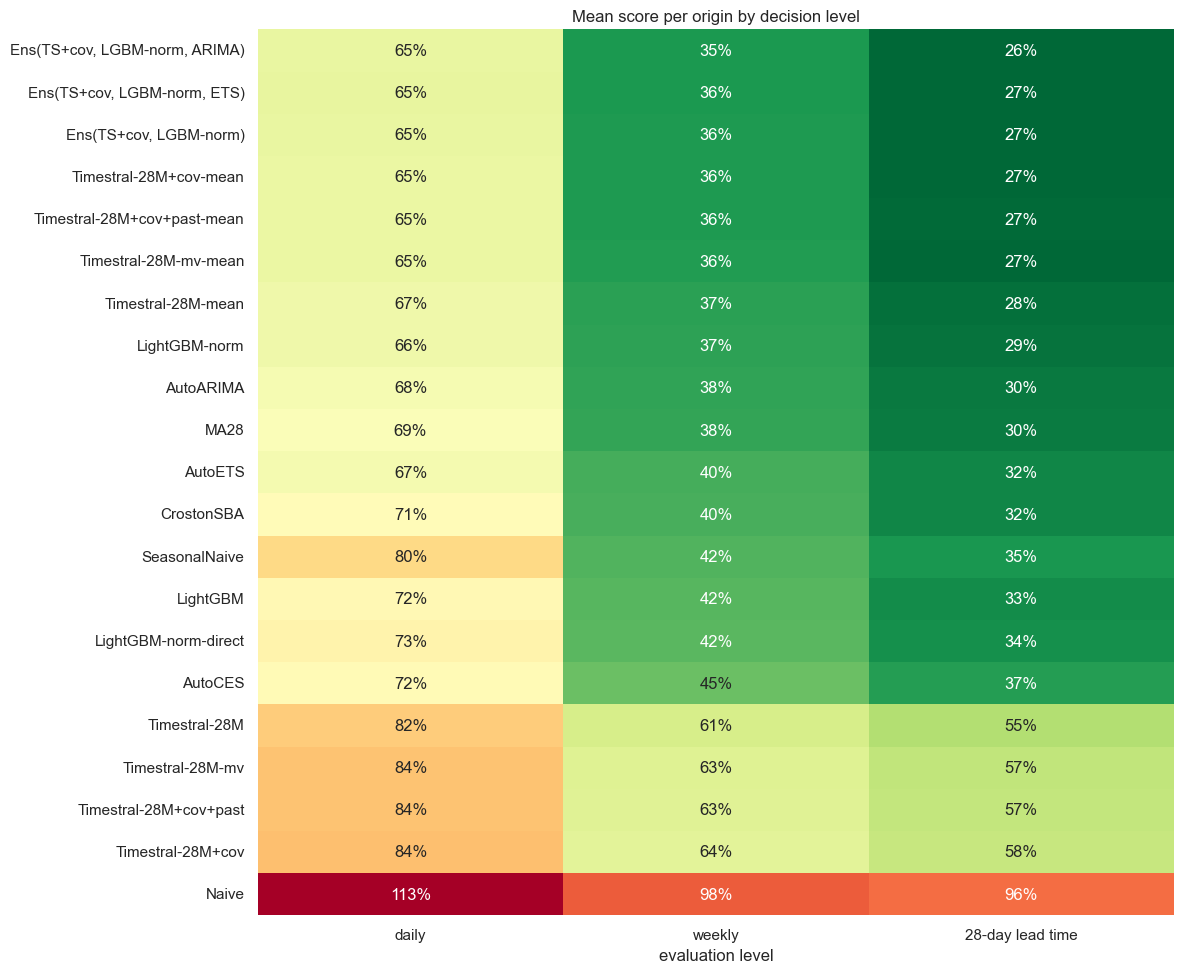

In [43]:
decision_levels = {"daily": 1, "weekly": 7, "28-day lead time": settings.horizon}
level_scores = {}
for name, days in decision_levels.items():
    agg_df = merged_df if days == 1 else aggregate_periods(df=merged_df, models=MODELS, days=days)
    level_scores[name] = fold_table(df=agg_df, models=MODELS, metric="score")["mean"]
decision_df = pd.DataFrame(level_scores).sort_values("weekly")

plot_heatmap(table=decision_df, xlabel="evaluation level",
             title="Mean score per origin by decision level")

plt.tight_layout()
plt.show()

Rank of the five best models at each level (1 = best): the top of the ranking does not change.

In [44]:
decision_df.rank().astype(int).head()

,daily,weekly,28-day lead time
model,,,
"Ens(TS+cov, LGBM-norm, ARIMA)",2,1,1
"Ens(TS+cov, LGBM-norm, ETS)",1,2,2
"Ens(TS+cov, LGBM-norm)",3,3,3
Timestral-28M+cov-mean,4,4,4
Timestral-28M+cov+past-mean,5,5,6


**Reading.**

* **Aggregation compresses the errors** (from about 65% daily to 35–38% weekly and 26–30% on the 28-day
  total) **but keeps the ranking at the top**: the ensembles and Timestral-28M+cov stay first at every
  level.
* **The gaps widen in relative terms.** On the 28-day total per series the ensemble with AutoARIMA scores
  26.4% and Timestral-28M+cov 26.7%, against 28.5% for LightGBM-norm, 29.5% for AutoARIMA and 30.0% for
  the moving average.
* **AutoETS drops** below the moving average at the weekly level (40.0% vs 38.1%), although it beats it
  on the daily score: its daily errors do not cancel within the week.

The right evaluation level depends on the replenishment process, and it can change which benchmark is a
fair comparison.

## 11. Limits and problems of Timestral found in this analysis

The headline result is positive, but the path to it ran into several issues that anyone using Timestral on
retail demand should know about. The cell below quantifies the most serious one, the constant-price
problem, on the last origin.

In [45]:
_, n_flat = mask_constant_covariate(inputs=inp, name="sell_price", window=settings.timestral_max_context)

print(f"Last origin: {n_flat:,} of {len(inp.unique_ids):,} series ({n_flat / len(inp.unique_ids):.0%}) "
      "have a flat price in the context and get it masked")

Last origin: 1,022 of 2,469 series (41%) have a flat price in the context and get it masked


With the mask, the largest mean forecast of each Timestral run stays below 90 units at every origin:
no blow-ups.

In [46]:
cols = ["Timestral-28M-mean", "Timestral-28M+cov-mean", "Timestral-28M+cov+past-mean",
        "Timestral-28M-mv-mean"]

merged_df.groupby("cutoff")[cols].max().round(0).rename(columns=lambda c: f"max {c}")

,max Timestral-28M-mean,max Timestral-28M+cov-mean,max Timestral-28M+cov+past-mean,max Timestral-28M-mv-mean
cutoff,,,,
2016-02-28,68.0,69.0,67.0,73.0
2016-03-27,84.0,79.0,79.0,81.0
2016-04-24,82.0,83.0,87.0,82.0


1. **The default point forecast is biased.** The median under-forecasts intermittent demand by about
   24%. The mean has to be approximated from 21 quantiles: the tails beyond q01 and q99 are truncated, and
   the result depends on the quantile grid.
2. **Covariates are fragile.** Timestral normalises every covariate row by its variability over the
   context. A price that never moved (41% of the series here) and then changes in the horizon becomes an
   extreme input and blows up the upper quantiles. The fix (masking flat prices as missing) works for the
   28M; the 209M stayed unstable and is left out of the analysis. Reported as
   [mistralai/timestral#7](https://github.com/mistralai/timestral/issues/7).
3. **`symmetric_averaging` negates the covariates.** The mirrored pass feeds the model negative prices,
   which are outside its training distribution. With the mask it does no harm, but the interaction is not
   documented.
4. **Covariates are expensive.** On CPU they multiply the inference time by about 18 (701 s against 39 s
   for three origins) for a 1.3-point gain.
5. **Event information is too coarse.** A single 0/1 event row cannot distinguish a store closure
   (Christmas) from a sporting event; on holiday windows Timestral over-forecasts by about 9%. Timestral
   accepts categorical covariates, which were not tried here.
6. **Multivariate forecasting needs shared covariates**, so item prices cannot be used, and it brought
   no accuracy gain.
7. **Possible training-data overlap.** M5 is public and widely used; we could not verify whether it is
   part of Timestral's pre-training corpus, which would flatter the zero-shot results.
8. **Small sample of origins.** Three main and three holiday windows; differences of about one point
   between models are within the origin-to-origin variation.
9. **No fine-tuning.** Everything is zero-shot; a fine-tuned Timestral may close the gaps on erratic and
   lumpy series and on holidays.

## 12. Conclusions

* **Zero-shot, Timestral-28M with known covariates is the best single model** on the main origins
  (score 65.2%, FVA +4.9% over the moving average), ahead of a tuned LightGBM and of AutoARIMA / AutoETS,
  provided the **mean of the quantiles** is used as the point forecast and flat prices are masked.
* **An equal-weight ensemble** of Timestral, LightGBM-norm and AutoETS adds 0.6 points: small, because the
  members make the same mistakes.
* **At the level of the decision** (weekly or 28-day totals) the advantage holds and widens in relative
  terms.
* **On holiday windows the advantage disappears**: Timestral over-forecasts by about 9% and simple
  exponential smoothing wins. This is the main caveat before using it for replenishment.
* **Past covariates and multivariate grouping** do not improve accuracy; the multivariate run is a cheap
  way to add store-level information.

**Next steps**

* Pass events as a **categorical covariate** (holiday type, store closure) instead of a single 0/1 row.
* **Fine-tune** the 28M on the series' own history, especially for erratic and lumpy demand.
* Use the **quantiles directly** for inventory decisions (safety stock at a target service level) instead
  of reducing them to a point forecast.
* Extend the backtest to more origins, departments and stores to tighten the comparison.